# Statistical Analysis: Health Insurance Cross Sell Prediction

Tests which features are statistically associated with `Response`, to justify feature handling in the model notebook rather than assuming. Data is loaded live from the project's MySQL/MariaDB database -- no CSV dependency.

**Story:** data -> descriptive statistics -> test selection -> significance testing -> multiple-testing correction -> interpretation -> implication for modeling.

## Instructions

1. Run `health_insurance_etl.ipynb` first so the `customers` table exists in `health_insurance_db` (XAMPP MySQL must be running).
2. Use the project's `.venv` kernel. Dependencies: `pip install -r app/requirements.txt`.
3. Run the cells from top to bottom. Review each test's assumptions and report effect sizes and confidence intervals alongside p-values.
4. Treat the 0.05 significance threshold as a convention, not proof. With 381,109 rows almost any real association is "significant", so the effect size is what drives the conclusions. The notebook applies Benjamini-Hochberg correction across all tests.

The analysis reads from MySQL and does not read the CSV directly. Statistical association does not prove causation.


## How to read the statistics in this notebook

Every test below produces the same kinds of numbers. Their meaning is fixed here once, and each results table then has a short "what each column means" note.

| Term | Meaning |
|---|---|
| **H0 / H1** | The null hypothesis (H0) always says "there is no association / no difference between the groups". H1 says there is. A test looks for evidence *against* H0. |
| **p-value** | The probability of seeing a difference at least this large if H0 were true. Small = unlikely to be chance. Below `alpha = 0.05` is called "statistically significant". With 381,109 rows almost every real difference, even a tiny one, gets a p-value near 0, so the p-value alone says very little here. |
| **Effect size** | *How big* the difference or association is, independent of sample size. This is the number that actually matters in this dataset. Two are used: **rank-biserial `r`** for numeric-vs-group comparisons and **Cramer's V** for categorical-vs-categorical. For both: ~0.1 = small, ~0.3 = medium, ~0.5+ = large. |
| **95% confidence interval (CI)** | The range that would contain the true value in 95% of repeated samples. A narrow CI means the estimate is precise; a CI that excludes 0 (for a difference) means the direction is reliable. |
| **Adjusted p-value (Benjamini-Hochberg)** | When many tests are run, some will look significant by luck. The BH procedure inflates each p-value to control the expected share of false positives among the "significant" results. Use the adjusted value, not the raw one, for the final call. |
| **Response groups** | Throughout, `Response = 0` means **not interested** in vehicle insurance and `Response = 1` means **interested**. Tables and charts use those words, not the bare numbers. |
| **Flag columns** | `Previously_Insured`: 0 = not insured, 1 = already has vehicle insurance. `Driving_License`: 0 = no license, 1 = has a license. |

## Import libraries

In [1]:
# Environment check: makes sure this kernel has every package the notebook needs before anything else runs.
# If it fails, either pick the kernel "Health Insurance (.venv)" (top-right kernel picker) or install the
# missing packages into the selected Python:  python -m pip install -r ../app/requirements.txt
import importlib.util
import sys

required = {'pandas': 'pandas', 'numpy': 'numpy', 'sqlalchemy': 'SQLAlchemy', 'pymysql': 'PyMySQL',
            'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'scipy': 'scipy', 'joblib': 'joblib'}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise ModuleNotFoundError(
        f'This kernel ({sys.executable}) is missing: {", ".join(missing)}. '
        'Fix: select the kernel "Health Insurance (.venv)" in the kernel picker (top-right), '
        f'or run:  "{sys.executable}" -m pip install {" ".join(missing)}'
    )
print(f'Environment OK: {sys.executable}')

Environment OK: D:\Practice\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)

# One consistent, academic chart style for the whole notebook.
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'axes.labelsize': 11, 'axes.labelpad': 8,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 10, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.alpha': 0.4, 'axes.axisbelow': True,
})
PRIMARY, ACCENT, NEUTRAL = '#3b6ea5', '#d1603d', '#9aa5b1'
thousands = FuncFormatter(lambda v, _: f'{v:,.0f}')


def fmt_p(p):
    """Readable p-value: values that underflow to 0.0 are reported as a bound, not as zero."""
    return 'p < 1e-300' if p == 0 else f'p = {p:.2g}'


def label_bars(ax, bars, labels, fontsize=9, offset=0.3):
    """Write one label above each bar, centred, without overlapping the bar."""
    for bar, text in zip(bars, labels):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + offset, text,
                ha='center', va='bottom', fontsize=fontsize,
                bbox={'boxstyle': 'round,pad=0.15', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9})

## 1. Load data from the MySQL database

Same source as the EDA notebook: the `customers` table in the local MySQL/MariaDB database (browsable in DBeaver) -- no CSV file is read here. Requires MySQL running in XAMPP and the `customers` table already populated by `health_insurance_etl.ipynb`.

In [3]:
from sqlalchemy import create_engine

DB_HOST = 'localhost'
DB_PORT = 3306
DB_USER = 'root'
DB_PASSWORD = ''  # XAMPP default: empty password
DB_NAME = 'health_insurance_db'

engine = create_engine(f'mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

COLUMN_RENAME_MAP = {
    'gender': 'Gender', 'age': 'Age', 'driving_license': 'Driving_License',
    'region_code': 'Region_Code', 'previously_insured': 'Previously_Insured',
    'vehicle_age': 'Vehicle_Age', 'vehicle_damage': 'Vehicle_Damage',
    'annual_premium': 'Annual_Premium', 'policy_sales_channel': 'Policy_Sales_Channel',
    'vintage': 'Vintage', 'response': 'Response',
}

# This machine has ~1.5 GB of free RAM. pd.read_sql() without a chunksize calls
# cursor.fetchall(), which materialises all 381,109 rows as Python tuples before the
# DataFrame is built -- that peak is what raised MemoryError here on an earlier run.
# stream_results=True switches PyMySQL to an unbuffered (server-side) cursor and
# chunksize converts the rows in batches, so peak memory stays a few tens of MB.
def load_customers(engine, chunksize=50_000):
    """Read the whole customers table into a DataFrame without a large memory spike."""
    with engine.connect().execution_options(stream_results=True, max_row_buffer=chunksize) as conn:
        chunks = list(pd.read_sql('SELECT * FROM customers', con=conn, chunksize=chunksize))
    return pd.concat(chunks, ignore_index=True)


df = load_customers(engine).rename(columns=COLUMN_RENAME_MAP)
print(f'Shape: {df.shape}')

Shape: (381109, 12)


In [4]:
RESPONSE_LABELS = {0: 'Not interested (0)', 1: 'Interested (1)'}
EFFECT_BANDS = [(0.1, 'small'), (0.3, 'medium'), (0.5, 'large')]  # same convention for rank-biserial r and Cramer's V
OVERALL_RATE = df['Response'].mean() * 100
print(f'{len(df):,} customers; {OVERALL_RATE:.2f}% interested (Response = 1)')

381,109 customers; 12.26% interested (Response = 1)


## 2. Descriptive statistics

Count, mean, median, standard deviation, min, max and quartiles for the continuous numeric features (`Age`, `Annual_Premium`, `Vintage`). `Region_Code` and `Policy_Sales_Channel` are excluded here even though they are numeric dtype -- they are arbitrary category codes, not measured quantities, so a mean/std for them would not be meaningful (see the EDA notebook's numeric-feature classification).

**What each column means:** `count` = number of customers with a value; `mean` = arithmetic average; `median` = the middle value (half of customers are below it); `std` = standard deviation, the typical distance from the mean; `min`/`max` = smallest and largest value; `25%`/`50%`/`75%` = quartiles (a quarter, half, three-quarters of customers are below that value); `skew` = asymmetry, 0 for a symmetric distribution, positive when there is a long tail of large values.

In [5]:
continuous_features = ['Age', 'Annual_Premium', 'Vintage']

desc = df[continuous_features].describe().T
desc['median'] = df[continuous_features].median()
desc['skew'] = df[continuous_features].skew()
desc = desc[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max', 'skew']]
desc

,count,mean,median,std,min,25%,50%,75%,max,skew
Age,381109.0,38.822584,36.0,15.511611,20.0,25.0,36.0,49.0,85.0,0.672539
Annual_Premium,381109.0,30564.389581,31669.0,17213.155057,2630.0,24405.0,31669.0,39400.0,540165.0,1.766087
Vintage,381109.0,154.347397,154.0,83.671304,10.0,82.0,154.0,227.0,299.0,0.003030


**Reading the table:** `Annual_Premium` has a strongly positive skew (≈ 1.77) and a long tail of high-premium customers (max 540,165 against a 75th percentile of ~39,400), confirmed by the boxplots/IQR check in the EDA notebook. Its mean (~30,564) is nevertheless slightly *below* its median (~31,669): the 17% of customers who pay exactly the 2,630 minimum pull the mean down more than the high tail pulls it up. Neither summary alone describes this shape, which is two-humped rather than a single skewed bell. `Age` is mildly right-skewed (customers skew younger, with a long tail toward older ages up to 85). `Vintage` is nearly symmetric (mean ≈ median, skew ≈ 0); it looks uniformly spread rather than concentrated. This non-normal profile is exactly why the numeric-vs-Response test below uses a rank-based method rather than assuming normality.

## 3. Numeric features vs. Response: test selection

**Choosing the test:** a two-sample comparison between the `Response == 0` and `Response == 1` groups could use a t-test (assumes approximately normal, similarly-shaped distributions) or the Mann-Whitney U test (rank-based, no normality assumption, robust to outliers and skew).

From the descriptive statistics above and the EDA notebook's skew/outlier check: `Annual_Premium` is heavily right-skewed with real outliers, and `Age` is moderately skewed -- neither meets the t-test's normality assumption well, and at this sample size (381,109 rows) a formal normality test (e.g. Shapiro-Wilk) would reject even trivial, practically meaningless deviations, so it is not useful for this decision. **Mann-Whitney U is used for all three features**, both because it fits the skewed features and to keep the comparison method consistent across all three.

For each feature this reports the test statistic and p-value, **plus an effect size** (rank-biserial correlation `r`, the natural effect size for Mann-Whitney: 0 = no difference in rank distributions, +-1 = complete separation) and a **95% confidence interval on the mean difference** between groups, to separate statistical significance from practical importance.

- H0 (null): the distribution of the feature is the same in both `Response` groups.
- H1 (alternative): the distributions differ.

In [6]:
def mannwhitney_effect_size(group0, group1):
    n0, n1 = len(group0), len(group1)
    u_stat, p_val = stats.mannwhitneyu(group0, group1, alternative='two-sided')
    rank_biserial_r = 1 - (2 * u_stat) / (n0 * n1)
    mean_diff = group1.mean() - group0.mean()
    se = np.sqrt(group0.var(ddof=1) / n0 + group1.var(ddof=1) / n1)
    ci_low, ci_high = mean_diff - 1.96 * se, mean_diff + 1.96 * se
    return u_stat, p_val, rank_biserial_r, mean_diff, ci_low, ci_high


group0 = df.loc[df['Response'] == 0]
group1 = df.loc[df['Response'] == 1]

mw_rows = []
for col in continuous_features:
    u_stat, p_val, r, mean_diff, ci_low, ci_high = mannwhitney_effect_size(group0[col], group1[col])
    mw_rows.append({
        'feature': col,
        'median_not_interested': group0[col].median(),
        'median_interested': group1[col].median(),
        'u_statistic': u_stat,
        'p_value': p_val,
        'rank_biserial_r': r,
        'mean_diff (interested - not)': mean_diff,
        'ci_95_low': ci_low,
        'ci_95_high': ci_high,
    })

mw_results = pd.DataFrame(mw_rows)
mw_results

,feature,median_not_interested,median_interested,u_statistic,p_value,rank_biserial_r,mean_diff (interested - not),ci_95_low,ci_95_high
0,Age,34.0,43.0,5.826171e+09,0.000000e+00,0.254001,5.257333,5.134644,5.380022
1,Annual_Premium,31504.0,33002.0,7.343669e+09,9.141298e-98,0.059696,1184.932467,1006.285159,1363.579774
2,Vintage,154.0,154.0,7.824345e+09,5.163010e-01,-0.001851,-0.267998,-1.078623,0.542628


**What each column means:** `median_not_interested` / `median_interested` = the median of the feature in each Response group; `u_statistic` = the Mann-Whitney test statistic (its raw size depends on the group sizes and is not interpretable on its own; it is only used to compute `p_value` and `r`); `p_value` = probability of a difference this large under H0; `rank_biserial_r` = effect size from -1 to +1, where 0 means the two groups' values are thoroughly mixed and larger magnitude means one group's values tend to be higher (here positive = interested customers have higher values); `mean_diff (interested - not)` = the average value among interested customers minus the average among not-interested ones, in the feature's own units (years, currency, days); `ci_95_low` / `ci_95_high` = the 95% confidence interval for that mean difference.

**Interpreting each feature** (rank-biserial `r`: ~0.1 small, ~0.3 medium, ~0.5 large -- same convention as Cramer's V below):

- **`Age`**: p ≈ 0 (statistically significant) with `r` ≈ 0.25 -- a small-to-medium effect, the largest of the three. Interested customers are about 5.3 years older on average (95% CI: 5.1-5.4 years), consistent with the EDA notebook's KDE plot. This is both statistically significant and practically the most relevant numeric feature.
- **`Annual_Premium`**: p ≈ 9e-98 (statistically significant given the huge sample size) but `r` ≈ 0.06 -- a negligible effect. The 95% CI on the mean difference (about 1,006-1,364) is entirely above zero, so the direction is real, but the overlap between the two groups' distributions is almost total. Treat this as **statistically significant but practically weak**.
- **`Vintage`**: p ≈ 0.52 -- **not statistically significant**, and `r` ≈ -0.002 confirms essentially zero effect. There is no evidence `Vintage` differs between the two `Response` groups at all.

### Effect size per numeric feature (chart)

Bar length is the rank-biserial `r` from the table above. The shaded bands mark the conventional small / medium / large thresholds, so a bar that stays inside the pale band is a negligible effect no matter how small its p-value.

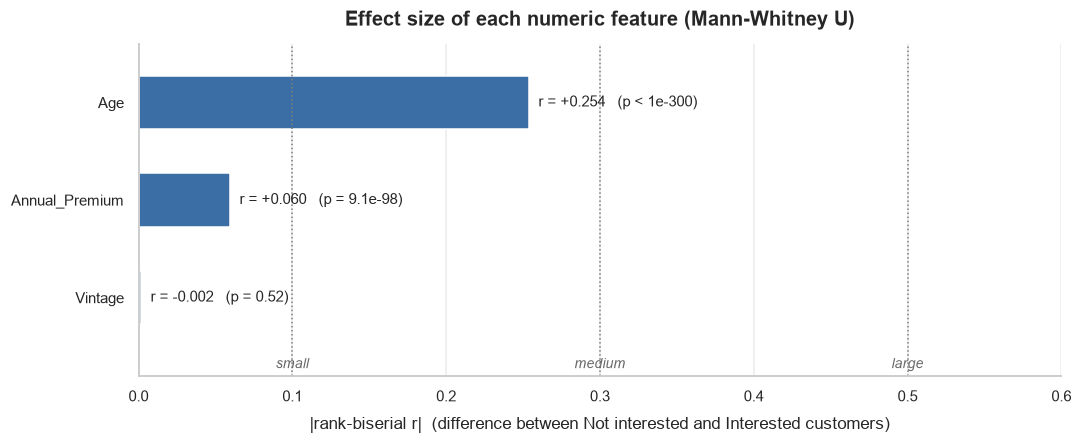

In [7]:
order = mw_results.sort_values('rank_biserial_r')

fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(order['feature'], order['rank_biserial_r'].abs(), height=0.55, color=PRIMARY)
for bar, r, p in zip(bars, order['rank_biserial_r'], order['p_value']):
    ax.text(bar.get_width() + 0.006, bar.get_y() + bar.get_height() / 2,
            f'r = {r:+.3f}   ({fmt_p(p)})', va='center', fontsize=10)
for threshold, name in EFFECT_BANDS:
    ax.axvline(threshold, color='grey', linestyle=':', linewidth=1)
    ax.text(threshold, -0.62, name, color='dimgrey', fontsize=9, style='italic', ha='center', va='top')
ax.set_ylim(-0.8, len(order) - 0.4)
ax.set_xlim(0, 0.6)
ax.grid(axis='y', visible=False)
ax.set_title('Effect size of each numeric feature (Mann-Whitney U)')
ax.set_xlabel('|rank-biserial r|  (difference between Not interested and Interested customers)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Reading the chart:** only `Age` crosses the "small" line (r ≈ +0.25, approaching medium); `Annual_Premium` (r ≈ +0.06) and `Vintage` (r ≈ 0.00) both sit inside the negligible zone. The p-values printed next to the bars show why they cannot be used alone: `Annual_Premium` has p ≈ 1e-97 yet an effect size that is practically nothing.

### Distribution by Response (boxplots)

Visual counterpart to the table above. Each panel compares one feature between the two Response groups. **How to read a box:** the box spans the 25th to 75th percentile of that group, the line inside is the median, the whiskers reach the last value within 1.5x the box height, and the dots beyond are outliers. If the two boxes sit at clearly different heights, the feature separates the groups; if they overlap almost completely, it does not. The median of each group is printed on the chart so the shift can be read as a number.

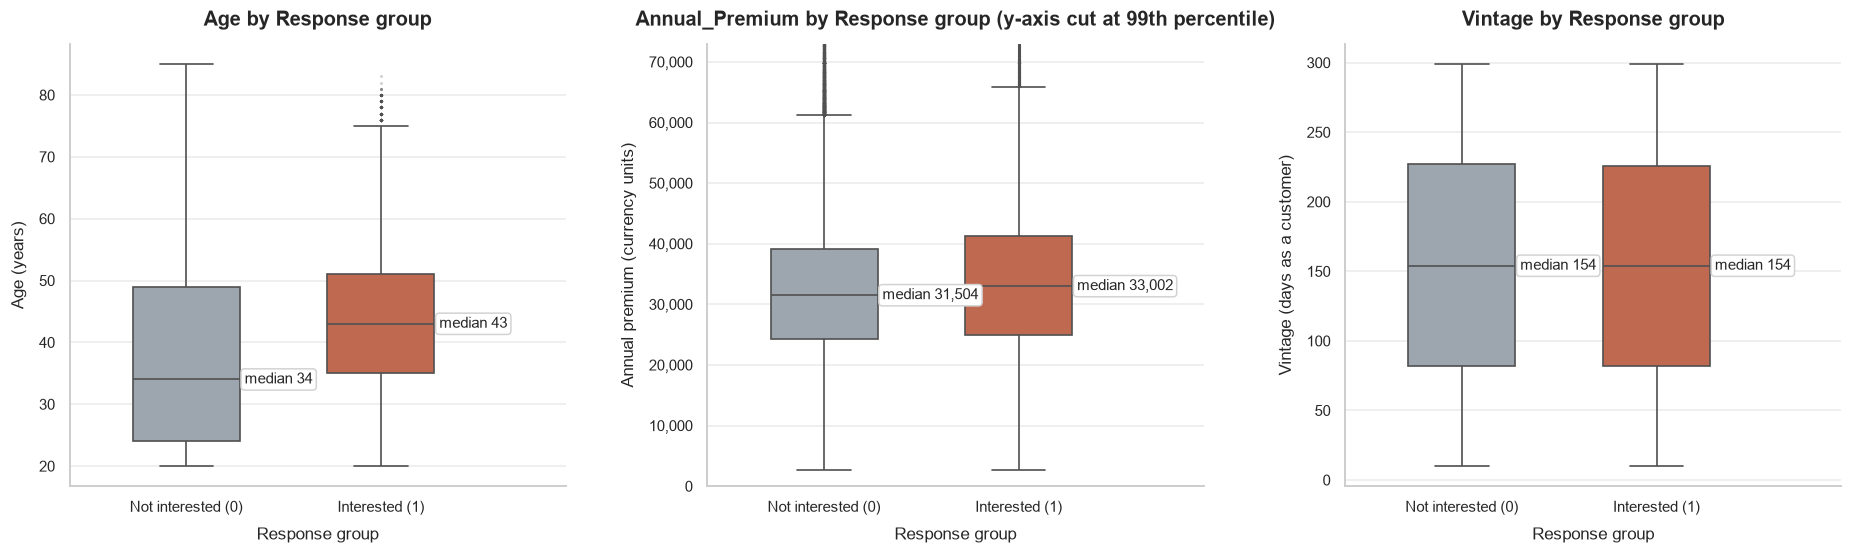

In [8]:
UNITS = {'Age': 'Age (years)', 'Annual_Premium': 'Annual premium (currency units)', 'Vintage': 'Vintage (days as a customer)'}
plot_df = df.assign(Response_label=df['Response'].map(RESPONSE_LABELS))
group_order = list(RESPONSE_LABELS.values())
GROUP_COLORS = {'Not interested (0)': NEUTRAL, 'Interested (1)': ACCENT}

fig, axes = plt.subplots(1, len(continuous_features), figsize=(17, 5.2))
for ax, col in zip(axes, continuous_features):
    sns.boxplot(data=plot_df, x='Response_label', y=col, order=group_order, ax=ax, hue='Response_label',
                palette=GROUP_COLORS, legend=False, width=0.55, linewidth=1.1,
                flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.25})
    medians = plot_df.groupby('Response_label')[col].median().reindex(group_order)
    for x, m in enumerate(medians):
        ax.text(x + 0.3, m, f'median {m:,.0f}', va='center', ha='left', fontsize=9.5,
                bbox={'boxstyle': 'round,pad=0.25', 'facecolor': 'white', 'edgecolor': 'lightgrey'})
    title_suffix = ''
    if col == 'Annual_Premium':  # outliers up to 540,165 would squash the boxes into a sliver
        ax.set_ylim(0, df[col].quantile(0.99))
        title_suffix = ' (y-axis cut at 99th percentile)'
    ax.set_title(f'{col} by Response group{title_suffix}')
    ax.set_xlabel('Response group')
    ax.set_ylabel(UNITS[col])
    ax.set_xlim(-0.6, 1.95)  # leave room for the median labels beside the right box
    ax.yaxis.set_major_formatter(thousands)
    ax.grid(axis='x', visible=False)
plt.tight_layout(w_pad=3)
plt.show()

**Reading the boxplots:** the `Age` boxes are visibly shifted (interested customers skew older) -- matching its effect size. The `Annual_Premium` boxes overlap almost entirely, with the shift barely visible -- matching its negligible effect size despite the significant p-value. The `Vintage` boxes are essentially identical between groups -- visual confirmation that there is no association.

## 4. Categorical features vs. Response: Chi-square test

**Why chi-square:** each categorical feature and `Response` are both discrete/unordered, so a chi-square test of independence is the appropriate test for association between two categorical variables.

- H0 (null): the feature is independent of `Response`.
- H1 (alternative): the feature is associated with `Response`.

**Assumption:** the chi-square approximation is only valid when expected cell counts are reasonably large -- the common rule of thumb is that no more than ~20% of cells should have an expected count below 5, and none should be below 1. This is checked explicitly below (`min_expected_freq`, `pct_cells_lt5`) rather than assumed, since two features here (`Region_Code`, `Policy_Sales_Channel`) have enough categories that this can plausibly fail.

Effect size is Cramer's V (~0.1 small, ~0.3 medium, ~0.5+ large), which is comparable across features regardless of table size.

In [ ]:
def cramers_v(contingency):
    # Effect size uses the uncorrected chi-square: SciPy applies Yates' continuity correction to
    # 2x2 tables by default, which is meant for the p-value, not for measuring association strength.
    chi2 = stats.chi2_contingency(contingency, correction=False)[0]
    n = contingency.sum().sum()
    r, k = contingency.shape
    return np.sqrt(chi2 / n / min(k - 1, r - 1))


categorical_cols = ['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Previously_Insured',
                    'Driving_License', 'Region_Code', 'Policy_Sales_Channel']

chi2_rows = []
for col in categorical_cols:
    contingency = pd.crosstab(df[col], df['Response'])
    chi2, p, dof, expected = stats.chi2_contingency(contingency)
    pct_cells_lt5 = (expected < 5).mean() * 100
    chi2_rows.append({
        'feature': col,
        'chi2': chi2,
        'dof': dof,
        'p_value': p,
        'cramers_v': cramers_v(contingency),
        'min_expected_freq': expected.min(),
        'pct_cells_lt5': pct_cells_lt5,
        'assumption_ok': pct_cells_lt5 == 0,
    })

chi2_results = pd.DataFrame(chi2_rows).sort_values('cramers_v', ascending=False).reset_index(drop=True)
chi2_results

**What each column means:** `chi2` = the chi-square statistic, a measure of how far the observed counts are from what independence would predict (bigger = more association, but its scale depends on `dof` and sample size, so it is not comparable across features); `dof` = degrees of freedom, `(number of categories - 1) x (2 - 1)`; `p_value` = probability of a chi2 this large under H0; `cramers_v` = the effect size, 0 to 1, comparable across features regardless of table size (~0.1 small, ~0.3 medium, ~0.5 large); `min_expected_freq` = the smallest count the test *expected* in any cell of the contingency table; `pct_cells_lt5` = percentage of cells with an expected count below 5; `assumption_ok` = `True` when no cell is below 5, i.e. the chi-square approximation is trustworthy.

**Reading the table:** every feature except `Policy_Sales_Channel` comfortably satisfies the expected-frequency assumption (`assumption_ok = True`, 0% of cells below 5) -- the sample is large enough that even `Region_Code`'s 53 categories are fine. **`Policy_Sales_Channel` fails the assumption**: with 155 categories, about a third of the contingency table's cells have an expected count below 5, so its chi-square p-value above is not trustworthy as reported and needs a remedy before it can be interpreted.

### Fixing the `Policy_Sales_Channel` assumption violation

Fisher's exact test is the textbook remedy when chi-square assumptions fail, but it is only defined (and only implemented in SciPy) for 2x2 tables -- `Policy_Sales_Channel` is a 155x2 table, so it doesn't apply here. The standard remedy for a sparse, high-cardinality categorical variable is instead to **collapse rare categories** into a single "Other" bucket, which restores valid expected counts without discarding the feature. Channels with fewer than 500 customers (the same threshold already used for this feature in the EDA notebook) are grouped together.

In [10]:
rare_channels = df['Policy_Sales_Channel'].value_counts()
rare_channels = rare_channels[rare_channels < 500].index
channel_collapsed = df['Policy_Sales_Channel'].where(~df['Policy_Sales_Channel'].isin(rare_channels), -1)

collapsed_table = pd.crosstab(channel_collapsed, df['Response'])
chi2_c, p_c, dof_c, expected_c = stats.chi2_contingency(collapsed_table)
pct_lt5_c = (expected_c < 5).mean() * 100
cramers_v_c = cramers_v(collapsed_table)

print(f'{len(rare_channels)} rare channels collapsed into "Other"; {channel_collapsed.nunique()} groups remain')
print(f'chi2={chi2_c:.2f}  dof={dof_c}  {fmt_p(p_c)}  min_expected={expected_c.min():.3f}  '
      f'pct_cells_lt5={pct_lt5_c:.2f}%  cramers_v={cramers_v_c:.4f}')

# Replace the invalid naive result for Policy_Sales_Channel with the corrected one
chi2_results.loc[chi2_results['feature'] == 'Policy_Sales_Channel',
                  ['chi2', 'dof', 'p_value', 'cramers_v', 'min_expected_freq', 'pct_cells_lt5', 'assumption_ok']] = \
    [chi2_c, dof_c, p_c, cramers_v_c, expected_c.min(), pct_lt5_c, pct_lt5_c == 0]
chi2_results = chi2_results.sort_values('cramers_v', ascending=False).reset_index(drop=True)
chi2_results

121 rare channels collapsed into "Other"; 35 groups remain
chi2=26054.62  dof=34  p < 1e-300  min_expected=62.385  pct_cells_lt5=0.00%  cramers_v=0.2615


,feature,chi2,dof,p_value,cramers_v,min_expected_freq,pct_cells_lt5,assumption_ok
0,Vehicle_Damage,47864.761801,1,0.000000e+00,0.354392,23127.215993,0.0,True
1,Previously_Insured,44357.964722,1,0.000000e+00,0.341162,21402.994629,0.0,True
2,Policy_Sales_Channel,26054.623821,34,0.000000e+00,0.261468,62.384751,0.0,True
3,Vehicle_Age,18771.889904,2,0.000000e+00,0.221937,1961.871722,0.0,True
4,Region_Code,7267.842469,52,0.000000e+00,0.138095,22.429095,0.0,True
5,Gender,1047.707758,1,7.665801e-230,0.052432,21451.039466,0.0,True
6,Driving_License,38.634117,1,5.111754e-10,0.010068,99.521449,0.0,True


**Result:** after collapsing rare channels, the assumption is satisfied (0% of cells below 5) and the conclusion is essentially unchanged -- `Policy_Sales_Channel` remains strongly associated with `Response` (Cramer's V ≈ 0.26, still the third-strongest categorical predictor), just now backed by a valid test rather than an invalid one. This corrected value (not the naive one) is used in the ranking chart and the multiple-testing correction below.

### Effect size per categorical feature (chart)

Bar length is Cramer's V from the corrected table above (the `Policy_Sales_Channel` value is the one computed after collapsing rare channels). The dotted lines mark the small / medium / large thresholds; the p-value is printed beside each bar to show that every feature is "significant" while only a few have a meaningful effect.

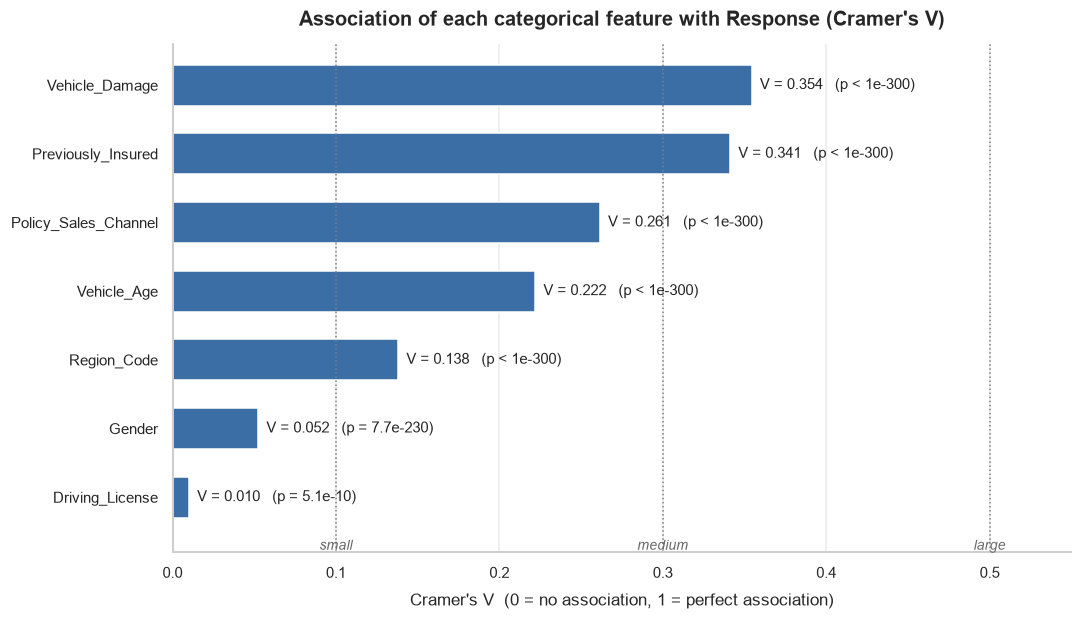

In [11]:
order = chi2_results.sort_values('cramers_v', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.8))
bars = ax.barh(order['feature'], order['cramers_v'], height=0.6, color=PRIMARY)
for bar, v, p in zip(bars, order['cramers_v'], order['p_value']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            f'V = {v:.3f}   ({fmt_p(p)})', va='center', fontsize=10)
for threshold, name in EFFECT_BANDS:
    ax.axvline(threshold, color='grey', linestyle=':', linewidth=1)
    ax.text(threshold, -0.62, name, color='dimgrey', fontsize=9, style='italic', ha='center', va='top')
ax.set_ylim(-0.8, len(order) - 0.4)
ax.set_xlim(0, 0.55)
ax.grid(axis='y', visible=False)
ax.set_title("Association of each categorical feature with Response (Cramer's V)")
ax.set_xlabel("Cramer's V  (0 = no association, 1 = perfect association)")
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Reading the chart:** `Vehicle_Damage` and `Previously_Insured` are the strongest categorical predictors by a clear margin (Cramer's V ≈ 0.35 and 0.34, medium-to-large effects), followed by `Policy_Sales_Channel` (≈ 0.26) and `Vehicle_Age` (≈ 0.22). `Region_Code` (≈ 0.14) and `Gender` (≈ 0.05) are weak, and `Driving_License` (≈ 0.01) is negligible despite being statistically significant (huge sample size makes even a trivial association "significant").

## 5. Multiple testing correction

Ten hypothesis tests are performed in total (3 Mann-Whitney U + 7 chi-square). Running many tests inflates the chance of at least one false positive (Type I error) purely by chance, even if every null hypothesis were true -- at alpha = 0.05 per test, the chance of at least one false "significant" result across 10 independent tests is noticeably higher than 5%. The **Benjamini-Hochberg (BH) false discovery rate (FDR)** procedure is used to correct for this: it controls the *expected proportion* of false positives among the tests called significant, which is less conservative (and more standard for exploratory feature screening like this) than a stricter family-wise correction such as Bonferroni.

In [12]:
def benjamini_hochberg(p_values, alpha=0.05):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    ranked = p_values[order]

    # BH adjusted p-values: step-up procedure, enforced monotone
    raw_adj = ranked * m / np.arange(1, m + 1)
    adj_sorted = np.minimum.accumulate(raw_adj[::-1])[::-1]
    adj_sorted = np.clip(adj_sorted, 0, 1)

    significant_sorted = adj_sorted <= alpha

    adj_p = np.empty(m)
    significant = np.empty(m, dtype=bool)
    adj_p[order] = adj_sorted
    significant[order] = significant_sorted
    return adj_p, significant


all_tests = pd.concat([
    mw_results[['feature', 'p_value']].assign(test='Mann-Whitney U'),
    chi2_results[['feature', 'p_value']].assign(test='Chi-square'),
], ignore_index=True)

all_tests['p_adj_bh'], all_tests['significant_after_bh'] = benjamini_hochberg(all_tests['p_value'], alpha=0.05)
all_tests = all_tests.sort_values('p_value').reset_index(drop=True)
all_tests

,feature,p_value,test,p_adj_bh,significant_after_bh
0,Age,0.000000e+00,Mann-Whitney U,0.000000e+00,True
1,Vehicle_Damage,0.000000e+00,Chi-square,0.000000e+00,True
2,Policy_Sales_Channel,0.000000e+00,Chi-square,0.000000e+00,True
3,Previously_Insured,0.000000e+00,Chi-square,0.000000e+00,True
4,Vehicle_Age,0.000000e+00,Chi-square,0.000000e+00,True
5,Region_Code,0.000000e+00,Chi-square,0.000000e+00,True
6,Gender,7.665801e-230,Chi-square,1.095114e-229,True
7,Annual_Premium,9.141298e-98,Mann-Whitney U,1.142662e-97,True
8,Driving_License,5.111754e-10,Chi-square,5.679726e-10,True
9,Vintage,5.163010e-01,Mann-Whitney U,5.163010e-01,False


**What each column means:** `feature` = the predictor tested; `test` = which test produced the p-value (Mann-Whitney U for the three numeric features, chi-square for the seven categorical ones); `p_value` = the raw p-value from the earlier table; `p_adj_bh` = the Benjamini-Hochberg adjusted p-value, always >= the raw one, which is what should be compared with alpha = 0.05 when ten tests are run together; `significant_after_bh` = `True` when `p_adj_bh` <= 0.05.

**Reading the table:** every test except `Vintage` remains significant after the Benjamini-Hochberg correction -- the raw p-values here are so small (mostly ≈ 0) that correction changes almost nothing in this particular dataset. `Vintage` (p ≈ 0.52 raw) stays clearly non-significant either way. The correction is still reported because it is the statistically correct thing to do when running multiple tests, not because it changed any conclusion here.

**Statistical vs. practical significance, restated:** `Driving_License` and `Annual_Premium` both remain "significant after correction," but their effect sizes (Cramer's V ≈ 0.01 and rank-biserial `r` ≈ 0.06) are negligible-to-small. With 381,109 rows, statistical significance is easy to achieve for almost any real (even tiny) association -- **effect size, not the p-value, is what should drive feature-importance decisions here.**

## 6. Response proportion confidence interval

Estimates the overall response rate with a 95% **Wilson** confidence interval, which quantifies the uncertainty in the observed sample proportion. Wilson is preferred over the normal approximation for proportions because it stays inside [0, 1] and is accurate even for rates far from 0.5. At this sample size the interval is very narrow, which is worth stating explicitly: the ~12.3% positive rate is a precise estimate for this population, and the class imbalance the model notebook has to handle is real, not sampling noise.


**What each column means:** `interested_customers` = number of customers with Response = 1; `observations` = all customers; `observed_proportion` = the share who are interested (the sample response rate); `ci_95_lower` / `ci_95_upper` = the 95% Wilson confidence interval for the true response rate.

In [13]:
def wilson_interval(successes, n, alpha=0.05):
    z = stats.norm.ppf(1 - alpha / 2)
    p_hat = successes / n
    denominator = 1 + z**2 / n
    centre = (p_hat + z**2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2)) / denominator
    return centre - half_width, centre + half_width


successes = int(df['Response'].sum())
observations = int(df['Response'].count())
ci_low, ci_high = wilson_interval(successes, observations)

proportion_summary = pd.DataFrame([{
    'interested_customers': successes,
    'observations': observations,
    'observed_proportion': successes / observations,
    'ci_95_lower': ci_low,
    'ci_95_upper': ci_high,
}])
proportion_summary


,interested_customers,observations,observed_proportion,ci_95_lower,ci_95_upper
0,46710,381109,0.122563,0.121526,0.123608


**Reading the table:** 46,710 of 381,109 customers are interested, a response rate of 12.26%, with a 95% confidence interval of about 12.15% to 12.36%. The interval is only 0.2 percentage points wide, so the ~12% figure is a precise description of this population. The class imbalance the model has to handle (roughly 7 not-interested customers for every interested one) is therefore a real property of the data, not sampling noise.

## 7. Multicollinearity check

The only other statistical check justified by this dataset: flags predictor pairs with |correlation| > 0.5. This matters for the coefficient- and distance-based models in the model notebook (Linear Regression, Logistic Regression, KNN). Tree/boosting models are unaffected. No further tests (e.g. ANOVA, time-series methods) are appropriate here: every predictor reduces to either a two-group numeric comparison or a categorical-vs-categorical association already covered above, and there is no time or panel structure in this data.

Those three models don't see `Region_Code` / `Policy_Sales_Channel` as raw code numbers. They see each code's **response rate** (target encoding, see the model notebook's Section 3). So the check runs on both versions: the raw codes, and `*_rate` columns holding each code's response rate. A code and its own `_rate` column are never used together, so that pair is not reported.

**What the output means:** each row is a pair of predictors and the absolute Pearson correlation between them (0 = unrelated, 1 = one is a perfect linear function of the other). Only pairs above 0.5 are listed. High values matter for linear models because two near-duplicate inputs make the coefficients unstable.

In [ ]:
numeric_for_corr = ['Age', 'Driving_License', 'Region_Code', 'Previously_Insured',
                    'Annual_Premium', 'Policy_Sales_Channel', 'Vintage']
corr_df = df[numeric_for_corr].assign(
    Region_Code_rate=df.groupby('Region_Code')['Response'].transform('mean'),
    Policy_Sales_Channel_rate=df.groupby('Policy_Sales_Channel')['Response'].transform('mean'),
)
corr_matrix = corr_df.corr().abs()

pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .dropna()  # pandas 3 keeps the masked lower-triangle cells as NaN; pandas 2 dropped them
    .sort_values(ascending=False)
)
same_feature = np.array([a.removesuffix('_rate') == b.removesuffix('_rate') for a, b in pairs.index])
pairs = pairs[~same_feature]

high_corr = pairs[pairs > 0.5]
print('Pairs with |r| > 0.5 (potential multicollinearity):')
print(high_corr if len(high_corr) else 'None found.')

print('\nAge vs each code, raw number and response-rate encoding:')
print(pairs.loc[[('Age', 'Policy_Sales_Channel'), ('Age', 'Policy_Sales_Channel_rate'),
                 ('Age', 'Region_Code'), ('Age', 'Region_Code_rate')]].round(3))

**Result:** the only pair above the 0.5 threshold is `Age` / `Policy_Sales_Channel` (≈ 0.58, moderate) -- not severe enough to require dropping a feature, but worth a light check on that pair's coefficients if the Logistic Regression baseline is used for anything beyond a sanity-check comparison.

## 8. Conclusions

**Strongest predictors** (by effect size, not just p-value): `Vehicle_Damage` (Cramer's V ≈ 0.35) and `Previously_Insured` (≈ 0.34) lead by a clear margin, both medium-to-large effects. `Policy_Sales_Channel` (≈ 0.26, after correcting its invalid chi-square assumption by collapsing rare categories) and `Vehicle_Age` (≈ 0.22) are next. Among numeric features, `Age` is the strongest (rank-biserial `r` ≈ 0.25, interested customers ~5.3 years older on average).

**Statistically significant but practically weak:** `Annual_Premium` (r ≈ 0.06), `Region_Code` (Cramer's V ≈ 0.14), `Gender` (≈ 0.05), and especially `Driving_License` (≈ 0.01) are all "significant" only because the sample is huge (381,109 rows) -- their actual effect sizes are small to negligible. This distinction matters for feature-importance judgments; p-values alone would overstate their relevance.

**No association found:** `Vintage` shows no relationship with `Response` at all (p ≈ 0.52, r ≈ -0.002, identical medians across groups) -- consistent with the EDA notebook's KDE plot. It is the only numeric feature that stays non-significant after the Benjamini-Hochberg correction.

**Data-quality / assumption issue found and fixed:** `Policy_Sales_Channel`'s naive chi-square test violated the expected-frequency assumption (33.2% of cells below 5, due to 155 sparse categories) -- collapsing rare channels into "Other" fixed this without changing the substantive conclusion.

**Multiple testing:** of 10 tests run, only `Vintage` fails to reach significance after Benjamini-Hochberg correction -- the same conclusion as the uncorrected p-values, so correction did not overturn any finding here, but is reported because 10 simultaneous tests warrant it in principle.

**Multicollinearity:** only `Age`/`Policy_Sales_Channel` exceeds |r| = 0.5 (≈ 0.58) -- not severe; no features need to be dropped.

**Implications for modeling:** feature importance should track effect size (`Vehicle_Damage`, `Previously_Insured`, `Policy_Sales_Channel`, `Vehicle_Age`, `Age`), not raw p-values. `Vintage` is a strong candidate to de-prioritize -- tree/boosting models will naturally ignore an uninformative feature, so it does not need to be dropped, but it should not be expected to help. `Driving_License`'s near-zero effect size means it will contribute almost nothing despite being "significant." This mirrors and formally confirms the visual patterns from the EDA notebook, closing the DATA -> EDA -> VISUALIZATION -> STATISTICAL TEST -> INTERPRETATION -> IMPLICATION FOR MODELING chain for this dataset.